# Keras & TensorFlow: ANN, CNN, VGG16, MobileNet

Follows `plan.md` with TensorFlow 2.21 / Keras 3: GPU setup, data, ANN / CNN / VGG16 / MobileNet,
training, confusion matrix and three ways to save a model.

## 1. Setup

In [1]:
import random, shutil, tarfile, zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential, Model
from keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# allocate GPU memory as needed instead of grabbing all of it at once
for gpu in tf.config.experimental.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

keras.utils.set_random_seed(42)
print('TF', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
MODELS_DIR = ROOT / 'models'
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

TF 2.21.0 | GPU: []


> If no GPU is found, TensorFlow runs on the CPU. On native Windows TensorFlow >= 2.11
> does not use the GPU at all (even with CUDA/cuDNN installed): use WSL2 or Google Colab.

In [2]:
def plot_history(history, title):
    h = history.history
    plt.figure(figsize=(6, 4))
    plt.plot(h['accuracy'], label='train')
    plt.plot(h['val_accuracy'], label='valid')
    plt.title(title); plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.show()


def plot_cm(y_true, y_pred, classes, title):
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues')
    plt.title(f'{title}: accuracy {np.mean(y_true == y_pred):.1%}'); plt.show()

## 2. ANN on tabular data

Synthetic exam results: students studied 0–10 hours. Most of those who studied less than 5 hours
failed (0), most of those who studied more passed (1). The network predicts the result from study hours.

In [3]:
def make_data(n):
    hours, labels = [], []
    for _ in range(n // 20):                 # 5% outliers
        hours += [random.uniform(0, 5), random.uniform(5, 10)]; labels += [1, 0]
    for _ in range(n):                       # 95% typical
        hours += [random.uniform(0, 5), random.uniform(5, 10)]; labels += [0, 1]
    return np.array(hours), np.array(labels)

train_x, train_y = make_data(1000)
test_x, test_y = make_data(200)
train_x, train_y = shuffle(train_x, train_y)  # shuffle before validation_split

scaler = MinMaxScaler()                       # scale to [0, 1]
train_x = scaler.fit_transform(train_x.reshape(-1, 1))
test_x = scaler.transform(test_x.reshape(-1, 1))

Epoch 1/30
189/189 - 1s - 5ms/step - accuracy: 0.5148 - loss: 0.6728 - val_accuracy: 0.5429 - val_loss: 0.6549
Epoch 2/30
189/189 - 0s - 1ms/step - accuracy: 0.5810 - loss: 0.6389 - val_accuracy: 0.6333 - val_loss: 0.6224
Epoch 3/30
189/189 - 0s - 1ms/step - accuracy: 0.6524 - loss: 0.6083 - val_accuracy: 0.7000 - val_loss: 0.5907
Epoch 4/30
189/189 - 0s - 1ms/step - accuracy: 0.7042 - loss: 0.5789 - val_accuracy: 0.7810 - val_loss: 0.5591
Epoch 5/30
189/189 - 0s - 1ms/step - accuracy: 0.7487 - loss: 0.5498 - val_accuracy: 0.8333 - val_loss: 0.5265
Epoch 6/30
189/189 - 0s - 1ms/step - accuracy: 0.7942 - loss: 0.5166 - val_accuracy: 0.8810 - val_loss: 0.4843
Epoch 7/30
189/189 - 0s - 1ms/step - accuracy: 0.8487 - loss: 0.4748 - val_accuracy: 0.9190 - val_loss: 0.4368
Epoch 8/30
189/189 - 0s - 1ms/step - accuracy: 0.8799 - loss: 0.4360 - val_accuracy: 0.9429 - val_loss: 0.3964
Epoch 9/30
189/189 - 0s - 1ms/step - accuracy: 0.9000 - loss: 0.4014 - val_accuracy: 0.9524 - val_loss: 0.3595
E

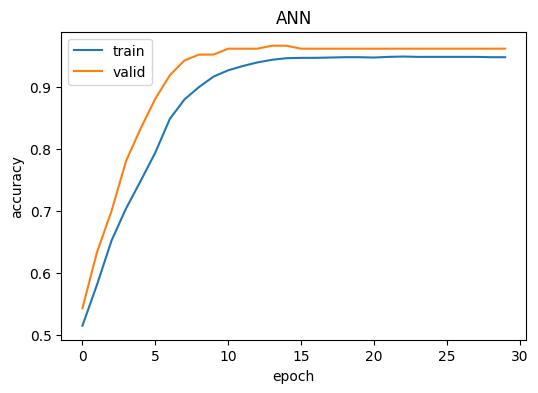

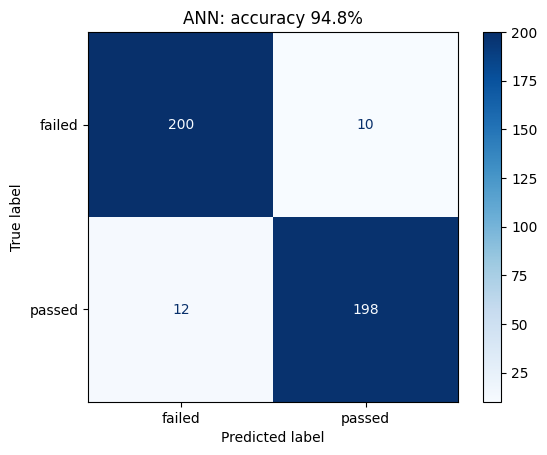

In [4]:
ann = Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(2, activation='softmax'),
])
ann.compile(optimizer=Adam(0.0001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = ann.fit(train_x, train_y, validation_split=0.1, batch_size=10, epochs=30, verbose=2)
plot_history(history, 'ANN')

pred = np.argmax(ann.predict(test_x, verbose=0), axis=1)
plot_cm(test_y, pred, ['failed', 'passed'], 'ANN')

Save and load the model:

In [5]:
ann.save(MODELS_DIR / 'ann.keras')
ann_loaded = keras.models.load_model(MODELS_DIR / 'ann.keras')
ann_loaded.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,928 (7.54 KB)

 Trainable params: 642 (2.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,286 (5.03 KB)

## 3. Horses vs Humans dataset

Set the number of images **per class** below (the two archives have ~630 images per class,
so `N_TRAIN + N_VALID + N_TEST` must not exceed that). Classes stay balanced 50/50.
The archives (~160 MB) are downloaded once; the split is rebuilt only when the sizes change.

In [6]:
# images per class
N_TRAIN, N_VALID, N_TEST = 450, 100, 50

HH_DIR = DATA_DIR / 'horses-vs-humans'
RAW_DIR = DATA_DIR / '_downloads' / 'horse-or-human'
URLS = ['https://storage.googleapis.com/learning-datasets/horse-or-human.zip',
        'https://storage.googleapis.com/learning-datasets/validation-horse-or-human.zip']


def split_sizes_match():
    sizes = {'train': N_TRAIN, 'valid': N_VALID, 'test': N_TEST}
    return all(len(list((HH_DIR / s / c).glob('*.png'))) == n
               for s, n in sizes.items() for c in ('horse', 'human'))


def prepare_horses_humans():
    if split_sizes_match():
        print('Dataset already exists'); return
    if HH_DIR.exists():
        print('Split sizes changed, rebuilding', HH_DIR)
        shutil.rmtree(HH_DIR)
    if not RAW_DIR.exists():
        # both archives have the same horses/ and humans/ folders, so merge them into one pool
        for url in URLS:
            zip_path = keras.utils.get_file(url.split('/')[-1], url, cache_dir=str(DATA_DIR), cache_subdir='_downloads')
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(RAW_DIR)

    need = N_TRAIN + N_VALID + N_TEST
    for src, cls in [('horses', 'horse'), ('humans', 'human')]:
        files = sorted((RAW_DIR / src).glob('*.png'))
        random.shuffle(files)
        if len(files) < need:
            raise ValueError(f'Only {len(files)} {cls} images, but {need} requested')
        parts = [('train', files[:N_TRAIN]),
                 ('valid', files[N_TRAIN:N_TRAIN + N_VALID]),
                 ('test', files[N_TRAIN + N_VALID:need])]
        for split, part in parts:
            (HH_DIR / split / cls).mkdir(parents=True, exist_ok=True)
            for f in part:
                shutil.copy(f, HH_DIR / split / cls / f.name)
    print('Done:', {s: len(list((HH_DIR / s).rglob('*.png'))) for s in ('train', 'valid', 'test')})


prepare_horses_humans()

149574867/149574867 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
11480187/11480187 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Done: {'train': 900, 'valid': 200, 'test': 100}


In [7]:
BATCH_SIZE = 10


def load_images(folder, preprocess, shuffle_data):
    ds = keras.utils.image_dataset_from_directory(
        folder, label_mode='categorical', image_size=(224, 224), batch_size=BATCH_SIZE, shuffle=shuffle_data)
    # images are streamed from disk; prefetch prepares the next batch while the model trains on the current one
    return ds.map(lambda x, y: (preprocess(x), y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


def labels_of(ds):
    return np.concatenate([np.argmax(y, axis=1) for _, y in ds])


vgg_pre = keras.applications.vgg16.preprocess_input
train_ds = load_images(HH_DIR / 'train', vgg_pre, True)
valid_ds = load_images(HH_DIR / 'valid', vgg_pre, True)
test_ds = load_images(HH_DIR / 'test', vgg_pre, False)   # no shuffle: keeps label order for the confusion matrix
test_y = labels_of(test_ds)
CLASSES = ['horse', 'human']

Found 900 files belonging to 2 classes.
Found 200 files belonging to 2 classes.
Found 100 files belonging to 2 classes.


## 4. Custom CNN

Epoch 1/10


C:\Users\chavv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


90/90 - 7s - 81ms/step - accuracy: 0.8156 - loss: 11.3057 - val_accuracy: 0.9200 - val_loss: 1.1927
Epoch 2/10
90/90 - 7s - 75ms/step - accuracy: 0.9356 - loss: 1.8007 - val_accuracy: 0.9400 - val_loss: 2.6865
Epoch 3/10
90/90 - 6s - 71ms/step - accuracy: 0.9756 - loss: 0.4596 - val_accuracy: 0.9800 - val_loss: 0.3067
Epoch 4/10
90/90 - 6s - 71ms/step - accuracy: 0.9644 - loss: 0.9168 - val_accuracy: 0.9250 - val_loss: 3.2708
Epoch 5/10
90/90 - 6s - 71ms/step - accuracy: 0.9844 - loss: 0.1834 - val_accuracy: 0.9800 - val_loss: 0.3396
Epoch 6/10
90/90 - 6s - 70ms/step - accuracy: 0.9933 - loss: 0.0669 - val_accuracy: 0.9550 - val_loss: 1.3821
Epoch 7/10
90/90 - 6s - 70ms/step - accuracy: 0.9989 - loss: 0.0247 - val_accuracy: 0.9900 - val_loss: 0.0834
Epoch 8/10
90/90 - 6s - 70ms/step - accuracy: 0.9989 - loss: 0.0023 - val_accuracy: 0.9850 - val_loss: 0.3382
Epoch 9/10
90/90 - 6s - 71ms/step - accuracy: 0.9978 - loss: 0.0075 - val_accuracy: 0.9850 - val_loss: 0.2019
Epoch 10/10
90/90 - 

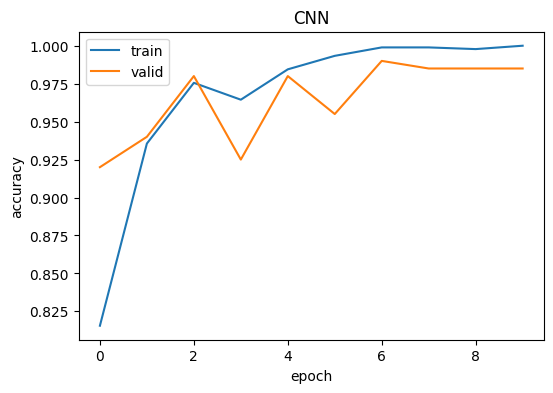

In [8]:
cnn = Sequential([
    keras.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(2, activation='softmax'),
])
cnn.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
history = cnn.fit(train_ds, validation_data=valid_ds, epochs=10, verbose=2)
plot_history(history, 'CNN')

Overfitting check: compare the final train and validation accuracy.
A large gap means the model memorizes the training images instead of learning general features.

In [9]:
# cnn.history keeps the last fit() of this model, so later cells reusing `history` don't affect it
train_acc = cnn.history.history['accuracy'][-1]
val_acc = cnn.history.history['val_accuracy'][-1]
gap = train_acc - val_acc
print(f'Train accuracy: {train_acc:.1%}')
print(f'Validation accuracy: {val_acc:.1%}')
print(f'Gap: {gap:.1%}', '-> the model overfits' if gap > 0.1 else '-> no strong overfitting')

Train accuracy: 100.0%
Validation accuracy: 98.5%
Gap: 1.5% -> no strong overfitting


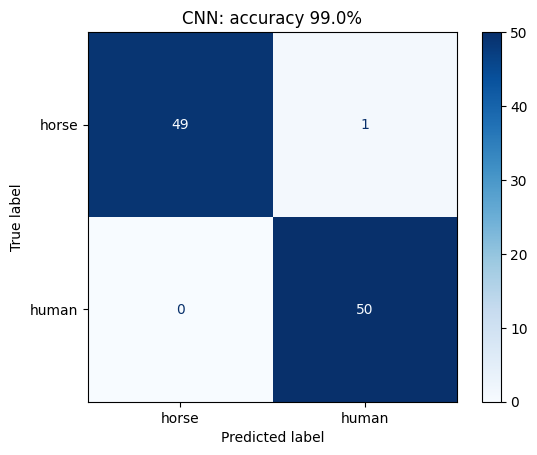

In [10]:
pred = np.argmax(cnn.predict(test_ds, verbose=0), axis=1)
plot_cm(test_y, pred, CLASSES, 'CNN')

### Data augmentation
Random rotations, shifts, zoom and flips make new training images out of existing ones.

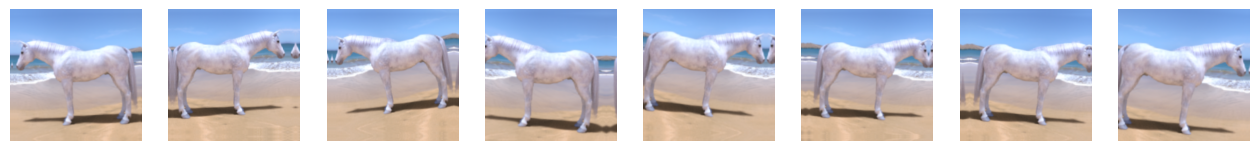

In [11]:
augment = Sequential([
    layers.RandomRotation(10 / 360),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
    layers.RandomFlip('horizontal'),
])

img_path = next((HH_DIR / 'train' / 'horse').glob('*.png'))
img = keras.utils.img_to_array(keras.utils.load_img(img_path, target_size=(224, 224)))
batch = augment(np.repeat(img[None], 8, axis=0), training=True).numpy()

plt.figure(figsize=(16, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1); plt.imshow(batch[i].astype('uint8')); plt.axis('off')
plt.show()

## 5. Fine-tuning VGG16

Take VGG16 trained on ImageNet, drop its last layer (1000 classes), freeze everything
and add a new `Dense(2)` layer. Only that layer is trained.

Epoch 1/5


C:\Users\chavv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


90/90 - 62s - 694ms/step - accuracy: 0.9622 - loss: 0.1260 - val_accuracy: 0.9950 - val_loss: 0.0258
Epoch 2/5
90/90 - 60s - 662ms/step - accuracy: 0.9978 - loss: 0.0203 - val_accuracy: 1.0000 - val_loss: 0.0124
Epoch 3/5
90/90 - 59s - 652ms/step - accuracy: 0.9989 - loss: 0.0107 - val_accuracy: 1.0000 - val_loss: 0.0079
Epoch 4/5
90/90 - 59s - 656ms/step - accuracy: 1.0000 - loss: 0.0068 - val_accuracy: 1.0000 - val_loss: 0.0056
Epoch 5/5
90/90 - 59s - 655ms/step - accuracy: 1.0000 - loss: 0.0048 - val_accuracy: 1.0000 - val_loss: 0.0043


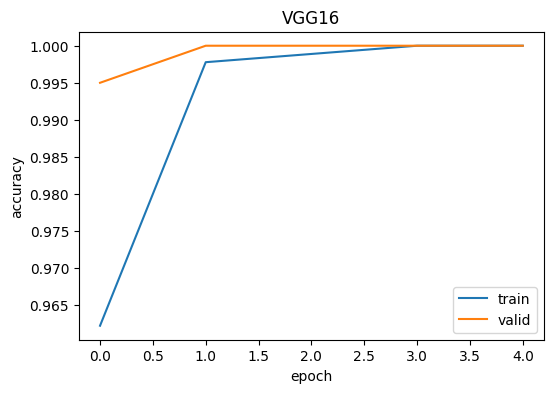

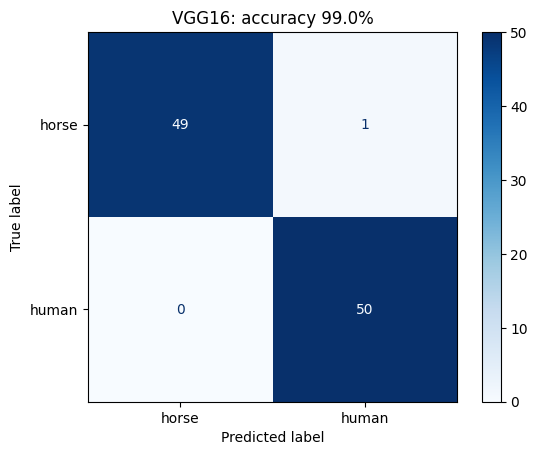

In [12]:
vgg16 = keras.applications.VGG16(weights='imagenet')

vgg = Sequential()
for layer in vgg16.layers[:-1]:
    layer.trainable = False
    vgg.add(layer)
vgg.add(layers.Dense(2, activation='softmax'))

vgg.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
history = vgg.fit(train_ds, validation_data=valid_ds, epochs=5, verbose=2)
plot_history(history, 'VGG16')

pred = np.argmax(vgg.predict(test_ds, verbose=0), axis=1)
plot_cm(test_y, pred, CLASSES, 'VGG16')

## 6. MobileNet
### Pretrained model as is

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


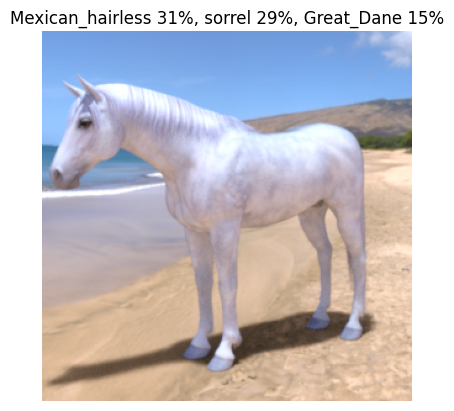

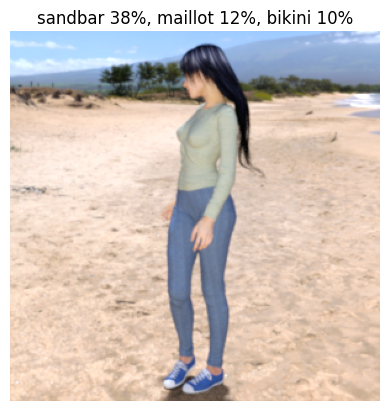

In [13]:
mobile = keras.applications.MobileNet(weights='imagenet')


def prepare_image(path):
    img = keras.utils.img_to_array(keras.utils.load_img(path, target_size=(224, 224)))
    return keras.applications.mobilenet.preprocess_input(img[None])   # shape (1, 224, 224, 3)


for path in [next((HH_DIR / 'test' / 'horse').glob('*.png')), next((HH_DIR / 'test' / 'human').glob('*.png'))]:
    top3 = keras.applications.mobilenet.decode_predictions(mobile.predict(prepare_image(path), verbose=0), top=3)[0]
    plt.imshow(keras.utils.load_img(path)); plt.axis('off')
    plt.title(', '.join(f'{name} {p:.0%}' for _, name, p in top3)); plt.show()

### Fine-tuning on Flowers

Photos of 5 kinds of flowers. Per class: 50 images for validation, 10 for test, the rest for training.

In [14]:
FLOWERS_DIR = DATA_DIR / 'flowers'
FLOWERS_URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
FLOWERS = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


def prepare_flowers():
    if (FLOWERS_DIR / 'test' / 'tulips').exists():
        print('Dataset already exists'); return
    tgz_path = keras.utils.get_file('flower_photos.tgz', FLOWERS_URL, cache_dir=str(DATA_DIR), cache_subdir='_downloads')
    with tarfile.open(tgz_path) as t:
        t.extractall(DATA_DIR / '_downloads', filter='data')
    raw = DATA_DIR / '_downloads' / 'flower_photos'
    for name in FLOWERS:
        files = sorted((raw / name).glob('*.jpg'))
        random.shuffle(files)
        for split, part in [('valid', files[:50]), ('test', files[50:60]), ('train', files[60:])]:
            (FLOWERS_DIR / split / name).mkdir(parents=True, exist_ok=True)
            for f in part:
                shutil.copy(f, FLOWERS_DIR / split / name / f.name)


prepare_flowers()

mob_pre = keras.applications.mobilenet.preprocess_input
flowers_train = load_images(FLOWERS_DIR / 'train', mob_pre, True)
flowers_valid = load_images(FLOWERS_DIR / 'valid', mob_pre, True)
flowers_test = load_images(FLOWERS_DIR / 'test', mob_pre, False)
flowers_test_y = labels_of(flowers_test)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step
Found 3370 files belonging to 5 classes.
Found 250 files belonging to 5 classes.
Found 50 files belonging to 5 classes.


Epoch 1/10


C:\Users\chavv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


337/337 - 28s - 82ms/step - accuracy: 0.8169 - loss: 0.5089 - val_accuracy: 0.9080 - val_loss: 0.2918
Epoch 2/10
337/337 - 24s - 70ms/step - accuracy: 0.9418 - loss: 0.1903 - val_accuracy: 0.9160 - val_loss: 0.2270
Epoch 3/10
337/337 - 24s - 71ms/step - accuracy: 0.9671 - loss: 0.1094 - val_accuracy: 0.9200 - val_loss: 0.2369
Epoch 4/10
337/337 - 24s - 70ms/step - accuracy: 0.9804 - loss: 0.0745 - val_accuracy: 0.9120 - val_loss: 0.2123
Epoch 5/10
337/337 - 23s - 69ms/step - accuracy: 0.9908 - loss: 0.0507 - val_accuracy: 0.9400 - val_loss: 0.2408
Epoch 6/10
337/337 - 24s - 71ms/step - accuracy: 0.9905 - loss: 0.0411 - val_accuracy: 0.9320 - val_loss: 0.2000
Epoch 7/10
337/337 - 24s - 71ms/step - accuracy: 0.9920 - loss: 0.0363 - val_accuracy: 0.9280 - val_loss: 0.2636
Epoch 8/10
337/337 - 24s - 72ms/step - accuracy: 0.9944 - loss: 0.0293 - val_accuracy: 0.9480 - val_loss: 0.2018
Epoch 9/10
337/337 - 24s - 71ms/step - accuracy: 0.9923 - loss: 0.0280 - val_accuracy: 0.9240 - val_loss: 0

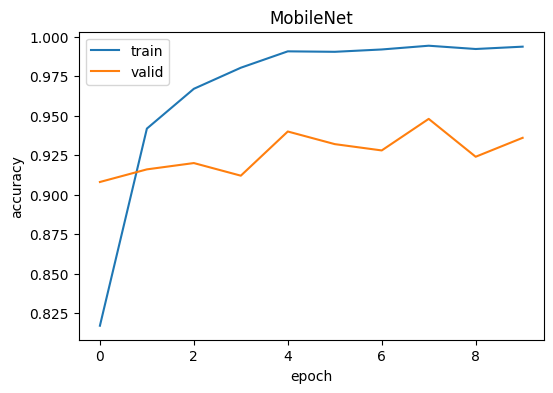

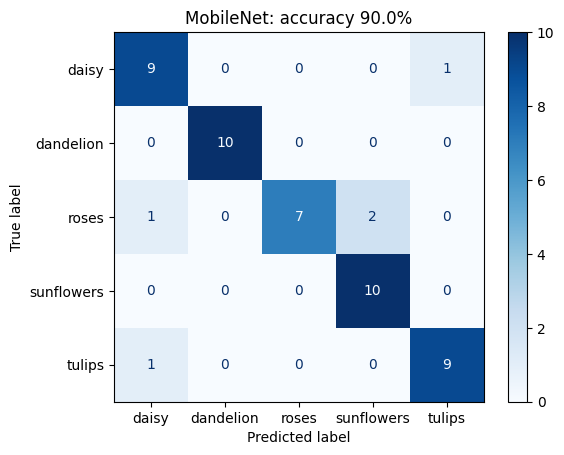

In [15]:
base = keras.applications.MobileNet(weights='imagenet')
# cut the model after global average pooling and add a 5-class head
pool = next(l for l in base.layers if isinstance(l, layers.GlobalAveragePooling2D))
x = layers.Flatten()(pool.output)
output = layers.Dense(5, activation='softmax')(x)
mob = Model(base.input, output)

# train only the last 23 layers
for layer in mob.layers[:-23]:
    layer.trainable = False

mob.compile(optimizer=Adam(0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
history = mob.fit(flowers_train, validation_data=flowers_valid, epochs=10, verbose=2)
plot_history(history, 'MobileNet')

pred = np.argmax(mob.predict(flowers_test, verbose=0), axis=1)
plot_cm(flowers_test_y, pred, FLOWERS, 'MobileNet')

## 7. Save and load the models

### Full model: architecture + weights + optimizer state

Training can continue right after loading. `.keras` is the Keras 3 format, `.h5` is the legacy one.

In [16]:
cnn.save(MODELS_DIR / 'cnn.keras')
vgg.save(MODELS_DIR / 'vgg16_horses_humans.keras')
mob.save(MODELS_DIR / 'mobilenet_flowers.keras')
mob.save(MODELS_DIR / 'mobilenet_flowers.h5')

mob_loaded = keras.models.load_model(MODELS_DIR / 'mobilenet_flowers.keras')
pred = np.argmax(mob_loaded.predict(flowers_test, verbose=0), axis=1)
print(f'Loaded MobileNet test accuracy: {np.mean(flowers_test_y == pred):.1%}')
print('Optimizer steps restored:', int(mob_loaded.optimizer.iterations))

Loaded MobileNet test accuracy: 90.0%
Optimizer steps restored: 3370


### Architecture only (JSON)

The rebuilt model has new random weights, so it has to be trained again. Keras 3 has no YAML export.

In [17]:
json_string = cnn.to_json()
(MODELS_DIR / 'cnn_architecture.json').write_text(json_string)

cnn_architecture = keras.models.model_from_json(json_string)
cnn_architecture.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │       401,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,262,408 (4.82 MB)

 Trainable params: 420,802 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 841,606 (3.21 MB)

### Weights only

The file name must end with `.weights.h5`. Loading needs a model with the same architecture.

In [18]:
cnn.save_weights(MODELS_DIR / 'cnn.weights.h5')

cnn2 = keras.models.clone_model(cnn)   # same architecture, new random weights
cnn2.load_weights(MODELS_DIR / 'cnn.weights.h5')
pred = np.argmax(cnn2.predict(test_ds, verbose=0), axis=1)
print(f'CNN with loaded weights, test accuracy: {np.mean(test_y == pred):.1%}')

CNN with loaded weights, test accuracy: 99.0%
